# 03 - Features: a pipeline that cannot leak

1. Every column checked against the moment of prediction (pickup)
2. The candidate features and why each one is allowed
3. The pipeline, raw rows in and a crawl probability out
4. Leak tests: proof that the pipeline cannot see the future
5. **Each feature judged on June**, step by step, including **the features that lost**
6. The two models (logistic regression and a decision tree) tuned on June
7. Where we stand against the baseline ladder

**July is not used in this notebook.** It is not even put in a variable.

In [1]:
import sys; sys.path.insert(0, "..")
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.base import clone
from src.clean import *
from src.features import *
from src.models import *
from src.evaluate import *
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 100)
FIG = Path("../reports/figures"); FIG.mkdir(parents=True, exist_ok=True)
REPORTS = Path("../reports")
BLUE, ORANGE, AQUA, GREY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#c9c8c2", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": INK, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
                     "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "lines.linewidth": 2})

df, _ = build_dataset()
train = df[df.split == "train"].reset_index(drop=True)
val = df[df.split == "validation"].reset_index(drop=True)
del df                                   # July stays out of this notebook
ytr, yva = train.crawl.to_numpy(), val.crawl.to_numpy()
print(f"train (May) {len(train):,} trips, crawl rate {ytr.mean():.3f};  validation (June) {len(val):,}, crawl rate {yva.mean():.3f}")

train (May) 187,694 trips, crawl rate 0.193;  validation (June) 186,184, crawl rate 0.185


## 1. The moment of prediction, column by column
At pickup the dispatcher knows **the pickup time, the pickup zone and the booked drop-off zone**. Everything else in the table is either part of the target or settled at the end of the trip. Every column of the cleaned table is classified below, and the code fails if a column is left unclassified.

In [2]:
INPUTS = {"tpep_pickup_datetime": "pickup time -> hour, weekday, rush, night",
          "PULocationID": "pickup zone -> zone flags, learned zone rates",
          "DOLocationID": "booked destination -> zone flags, planned distance, pair rate",
          "pickup_borough": "from the pickup zone", "dropoff_borough": "from the drop-off zone"}
WHY_FORBIDDEN = {"tpep_dropoff_datetime": "end of the trip", "duration_min": "part of the target", "speed_mph": "is the target",
                 "crawl": "the label", "trip_distance": "measured during the trip (target numerator); used only to learn the planned distance from May",
                 "RatecodeID": "set at the end", "nonstandard_rate": "from RatecodeID", "payment_type": "settled at the end",
                 "is_flex": "from payment_type", "passenger_count": "entered by the driver, missing for flex",
                 "store_and_fwd_flag": "how the record was sent, after the trip", "long_trip": "from the measured distance"}
BOOKKEEPING = {"VendorID": "which meter company; not a trip property", "month": "the split itself", "split": "the split itself",
               "pickup_zone": "name only (the ID is used)", "dropoff_zone": "name only (the ID is used)",
               "request_source": "NOT_IN_TRAINING: empty for every May trip, filled only for flex trips from June, so nothing can be learned from it"}
rows = []
for c in train.columns:
    if c in INPUTS: rows.append((c, "INPUT at pickup", INPUTS[c]))
    elif c in FORBIDDEN: rows.append((c, "FORBIDDEN", WHY_FORBIDDEN.get(c, "settled at the end of the trip (money)")))
    elif c in BOOKKEEPING: rows.append((c, "not used", BOOKKEEPING[c]))
    else: raise AssertionError(f"column {c} is not classified")
pd.DataFrame(rows, columns=["column", "status", "why"]).set_index("column")

,status,why
column,,
VendorID,not used,which meter company; not a trip property
tpep_pickup_datetime,INPUT at pickup,"pickup time -> hour, weekday, rush, night"
tpep_dropoff_datetime,FORBIDDEN,end of the trip
passenger_count,FORBIDDEN,"entered by the driver, missing for flex"
trip_distance,FORBIDDEN,measured during the trip (target numerator); used only to learn the planned distance from May
RatecodeID,FORBIDDEN,set at the end
store_and_fwd_flag,FORBIDDEN,"how the record was sent, after the trip"
PULocationID,INPUT at pickup,"pickup zone -> zone flags, learned zone rates"
DOLocationID,INPUT at pickup,"booked destination -> zone flags, planned distance, pair rate"


In [3]:
check_no_forbidden(ALL_FEATS)
print(f"{len(ALL_FEATS)} candidate features, none on the FORBIDDEN list of {len(FORBIDDEN)} columns")

18 candidate features, none on the FORBIDDEN list of 23 columns


## 2. The candidate features
| Group | Features | What | Why it is allowed at pickup |
|---|---|---|---|
| time | `hour`, `weekday`, `is_weekend`, `is_rush` (weekday 8 to 19h), `is_night` (0 to 5h) | when the trip starts | the clock at pickup |
| zone flags | `pu_manhattan`, `do_manhattan`, `cross_borough`, `same_zone`, `pu_airport`, `do_airport` | where it starts and is going | the two zones are known at booking |
| planned distance | `plan_dist`, `log_plan_dist` | estimated route length: the median measured distance of **May** trips between the same two zones (pickup-zone median if the pair has fewer than 5 May trips) | it stands in for what a routing engine says at booking. It is learned from past trips, never from the trip itself |
| zone rates | `pu_rate`, `do_rate` | share of May trips from / to this zone that crawled, shrunk towards the city rate | learned from May labels only |
| pair rate | `pair_rate`, `log_pair_n` | crawl share for this pickup-drop-off pair, shrunk towards the pickup-zone rate; how many May trips the pair had | learned from May labels only |
| zone x time rate | `pu_slot_rate` | crawl share of the pickup zone in this time slot (weekday/weekend x night/day/evening) | learned from May labels only |

**The trap: learned statistics.** The rates and the planned distance are built from labels and measured distances. On a May trip, using all of May would include the trip's own label and distance, so the model would look better on May than it can ever be. `ZoneHistory` therefore computes them **out-of-fold** on May (5 folds: each trip's statistics come from the other 80% of May) and learns once from all of May for June and July.

## 3. The pipeline

In [4]:
pipe = make_pipeline(make_logreg(), ALL_FEATS, scale=True)
pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('prep', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,m,20.0
,min_pair_n,5
,n_folds,5
,oof,True
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold

In [5]:
pipe.fit(train, ytr)
p_pipe = pipe.predict_proba(val)[:, 1]
print(f"logistic regression, all candidate features, June PR AUC {average_precision_score(yva, p_pipe):.3f}")

logistic regression, all candidate features, June PR AUC 0.630


`pipe.fit(train, y)` calls `fit_transform` on the features step, so May gets out-of-fold statistics. `pipe.predict_proba(val)` calls `transform`, which uses statistics learned from May only. The same object is all that notebook 04 needs.

## 4. Leak tests

In [6]:
# 4a. The pipeline never reads a forbidden column at prediction time:
#     blank every forbidden column of June (including the label) and the predictions must not change.
blank = val.copy()
for c in FORBIDDEN + NOT_IN_TRAINING:
    if c in blank:
        blank[c] = pd.NaT if pd.api.types.is_datetime64_any_dtype(blank[c]) else np.nan
assert np.allclose(pipe.predict_proba(blank)[:, 1], p_pipe), "a forbidden column changes predictions"
print("4a pass: June predictions are identical with every forbidden (and not-in-training) column blanked")

# 4b. Statistics come from May only
hist = pipe.named_steps["features"].history_
assert hist.n_train_ == len(train)
print(f"4b pass: ZoneHistory learned from {hist.n_train_:,} May trips and nothing else")

# 4c. Shuffled May labels must give no skill on June (PR AUC ~ June's positive rate)
rng = np.random.default_rng(0)
p_shuf = clone(pipe).fit(train, rng.permutation(ytr)).predict_proba(val)[:, 1]
ap_shuf = average_precision_score(yva, p_shuf)
print(f"4c: shuffled labels -> June PR AUC {ap_shuf:.3f} vs positive rate {yva.mean():.3f}")
assert ap_shuf < yva.mean() * 1.15 + 0.03 or ap_shuf < 0.5 * average_precision_score(yva, p_pipe)

4a pass: June predictions are identical with every forbidden (and not-in-training) column blanked
4b pass: ZoneHistory learned from 187,694 May trips and nothing else


4c: shuffled labels -> June PR AUC 0.186 vs positive rate 0.185


**4d. Why out-of-fold matters.** On the real data the May-to-June gap is larger with in-sample statistics than with out-of-fold ones (about 0.08 vs 0.07): the in-sample tree looks better on May than it is. The same deep tree, once with out-of-fold statistics and once with statistics computed on all of May including each trip itself. If the in-sample version scores much higher on May than on June, that gap is leakage: the tree has memorised small zone pairs through their own labels.

In [7]:
deep = make_tree(12, min_samples_leaf=20)
rows = {}
for name, oof in [("out-of-fold (ours)", True), ("in-sample (leaky)", False)]:
    step = CrawlFeatures(oof=oof)
    Xtr = step.fit_transform(train, ytr); Xva = step.transform(val)
    t = clone(deep).fit(Xtr, ytr)
    rows[name] = {"May PR AUC": average_precision_score(ytr, t.predict_proba(Xtr)[:, 1]),
                  "June PR AUC": average_precision_score(yva, t.predict_proba(Xva)[:, 1])}
oof_tab = pd.DataFrame(rows).T; oof_tab["gap"] = oof_tab["May PR AUC"] - oof_tab["June PR AUC"]
oof_tab.round(3)

,May PR AUC,June PR AUC,gap
out-of-fold (ours),0.673,0.607,0.066
in-sample (leaky),0.695,0.611,0.083


## 5. Each feature judged on June
The feature tables are built once (`build_matrix`, the same code the pipeline runs), and each model is then fitted on a subset of columns. The result is checked against the full pipeline so the shortcut is honest.

**Rule:** a group is added in the order below; it is **kept** if it raises June PR AUC by at least `MIN_GAIN` = 0.002 for at least one of the two models, otherwise it **loses** and is left out of later steps.

In [8]:
M, zh = build_matrix(train, {"val": val})
Xtr, Xva = M["train"], M["val"]
TREE = dict(max_depth=8, min_samples_leaf=200)
def june_score(feats, kind):
    model = make_model(make_logreg(), feats, scale=True) if kind == "logreg" else make_model(make_tree(**TREE), feats, scale=False)
    model.fit(Xtr, ytr)
    return average_precision_score(yva, model.predict_proba(Xva)[:, 1])

assert np.isclose(june_score(ALL_FEATS, "logreg"), average_precision_score(yva, p_pipe), atol=1e-6)
print("shortcut gives the same June score as the full pipeline")

shortcut gives the same June score as the full pipeline


In [9]:
MIN_GAIN = 0.002
kept, steps = [], []
prev = {"logreg": yva.mean(), "tree": yva.mean()}         # no features = no skill
for group, feats in GROUPS.items():
    trial = kept + feats
    s = {k: june_score(trial, k) for k in ("logreg", "tree")}
    gain = {k: s[k] - prev[k] for k in s}
    win = max(gain.values()) >= MIN_GAIN
    steps.append({"step": f"+ {group}", "features": ", ".join(feats), "logreg PR AUC": s["logreg"], "logreg gain": gain["logreg"],
                  "tree PR AUC": s["tree"], "tree gain": gain["tree"], "decision": "kept" if win else "LOST"})
    if win:
        kept, prev = trial, s
steps = pd.DataFrame(steps).set_index("step")
steps.round(4)

,features,logreg PR AUC,logreg gain,tree PR AUC,tree gain,decision
step,,,,,,
+ time,"hour, weekday, is_weekend, is_rush, is_night",0.3208,0.1354,0.3257,0.1403,kept
+ zone flags,"pu_manhattan, do_manhattan, cross_borough, same_zone, pu_airport, do_airport",0.3683,0.0475,0.3708,0.0451,kept
+ planned distance,"plan_dist, log_plan_dist",0.4327,0.0644,0.4254,0.0546,kept
+ zone rates,"pu_rate, do_rate",0.5920,0.1593,0.5951,0.1698,kept
+ pair rate,"pair_rate, log_pair_n",0.6227,0.0307,0.6096,0.0145,kept
+ zone x time rate,pu_slot_rate,0.6304,0.0077,0.6101,0.0005,kept


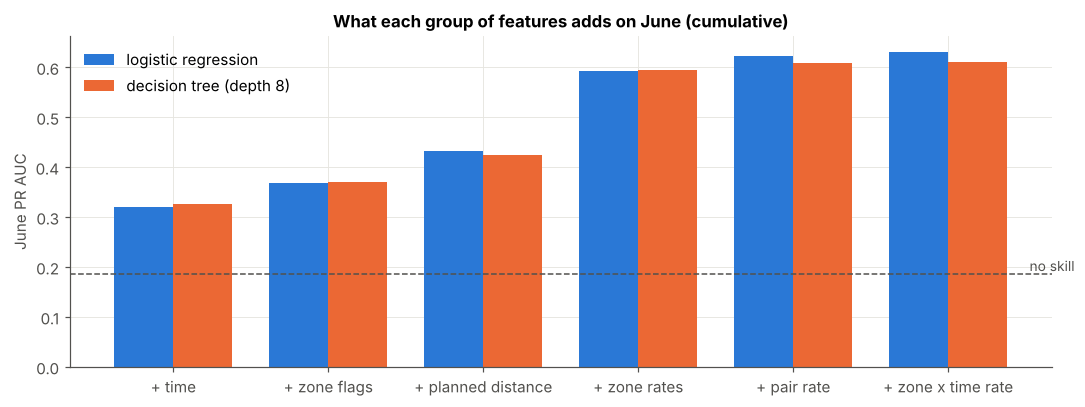

In [10]:
fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(steps)); w = 0.38
ax.bar(x - w/2, steps["logreg PR AUC"], w, color=BLUE, label="logistic regression")
ax.bar(x + w/2, steps["tree PR AUC"], w, color=ORANGE, label="decision tree (depth 8)")
ax.axhline(yva.mean(), color=INK, lw=1, ls="--"); ax.text(len(steps) - 0.5, yva.mean(), " no skill", va="bottom", color=INK, fontsize=9)
for i, d in enumerate(steps.decision):
    if d == "LOST": ax.text(i, max(steps.iloc[i][["logreg PR AUC", "tree PR AUC"]]) + 0.01, "lost", ha="center", color=INK, fontsize=9, fontweight="bold")
ax.set_xticks(x, steps.index, rotation=0); ax.set_ylabel("June PR AUC")
ax.set_title("What each group of features adds on June (cumulative)"); ax.legend(frameon=False, loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "03_feature_steps.png", bbox_inches="tight"); plt.show()

**Feature by feature.** Starting from the kept groups, each single feature is judged by removing it: the June PR AUC lost without it, for both models. Then a backward elimination: the weakest feature is dropped if removing it costs less than `MIN_GAIN` for both models, the rest are re-scored, and this repeats until every remaining feature earns its place.

In [11]:
def removal_losses(feats):
    base = {k: june_score(feats, k) for k in ("logreg", "tree")}
    out = {}
    for f in feats:
        rest = [g for g in feats if g != f]
        out[f] = {k: base[k] - june_score(rest, k) for k in base}
    return pd.DataFrame(out).T.rename(columns={"logreg": "logreg loss if removed", "tree": "tree loss if removed"})

abl = removal_losses(kept)                          # first round: every kept feature, judged alone
KEPT, lost_alone, losses = list(kept), [], abl.copy()
while len(KEPT) > 1:
    worst = losses.max(axis=1).idxmin()
    if losses.loc[worst].max() >= MIN_GAIN:
        break
    KEPT.remove(worst); lost_alone.append(worst)
    losses = removal_losses(KEPT)
abl["decision"] = ["LOST (adds nothing once the others are in)" if f in lost_alone else "kept" for f in abl.index]
display(abl.sort_values("logreg loss if removed", ascending=False).round(4))
s_final = {k: june_score(KEPT, k) for k in ("logreg", "tree")}
print(f"KEPT ({len(KEPT)}):", KEPT)
print(f"June PR AUC with the kept features: logistic {s_final['logreg']:.4f}, tree {s_final['tree']:.4f}")

,logreg loss if removed,tree loss if removed,decision
pair_rate,0.0246,0.0181,kept
hour,0.0205,0.0083,kept
pu_slot_rate,0.0077,0.0005,kept
weekday,0.0054,0.0021,kept
pu_rate,0.0036,0.0004,kept
do_rate,0.0027,0.0026,kept
cross_borough,0.0023,-0.0001,LOST (adds nothing once the others are in)
log_pair_n,0.0022,-0.0006,LOST (adds nothing once the others are in)
is_rush,0.0015,0.0089,kept
plan_dist,0.0013,0.0000,LOST (adds nothing once the others are in)


KEPT (7): ['hour', 'weekday', 'is_rush', 'pu_rate', 'do_rate', 'pair_rate', 'pu_slot_rate']
June PR AUC with the kept features: logistic 0.6270, tree 0.6109


### The features that lost, and the ones never allowed
Three kinds: groups that did not help on June, single features that add nothing once the others are in, and columns that would help but are **not known at pickup**. The last kind is scored only to show what we gave up. None of them is in the model.

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

def june_extra(extra_tr, extra_va, base_feats, kind):
    # June PR AUC with extra columns that make_prep would refuse (for reporting only)
    Xa, Xb = Xtr[base_feats].copy(), Xva[base_feats].copy()
    for k in extra_tr:
        Xa[k], Xb[k] = np.asarray(extra_tr[k], float), np.asarray(extra_va[k], float)
    if kind == "logreg":
        cat = [f for f in Xa.columns if f in CATEGORICAL]; num = [f for f in Xa.columns if f not in cat]
        model = Pipeline([("prep", ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cat),
                                                      ("num", StandardScaler(), num)])), ("m", make_logreg())])
    else:
        model = make_tree(**TREE)
    model.fit(Xa, ytr)
    return average_precision_score(yva, model.predict_proba(Xb)[:, 1])

lost = [{"feature": f"{step.replace('+ ', '')} (group)", "kind": "lost on June",
         "June gain (best model)": max(r["logreg gain"], r["tree gain"]), "why": f"added less than MIN_GAIN = {MIN_GAIN}"}
        for step, r in steps[steps.decision == "LOST"].iterrows()]
lost += [{"feature": f, "kind": "lost on June", "June gain (best model)": float(abl.loc[f, ["logreg loss if removed", "tree loss if removed"]].max()),
          "why": "adds nothing once the others are in"} for f in lost_alone]

nf = [f for f in KEPT if f not in ("plan_dist", "log_plan_dist")]
oracle_tr = {"log_measured_dist": np.log1p(train.trip_distance)}; oracle_va = {"log_measured_dist": np.log1p(val.trip_distance)}
rejected = {
    "is_flex (payment type 0)": ({"is_flex": train.is_flex}, {"is_flex": val.is_flex}, KEPT, "payment is settled at the end of the trip"),
    "passenger_count": ({"pc": train.passenger_count.fillna(0)}, {"pc": val.passenger_count.fillna(0)}, KEPT, "entered by the driver, missing for every flex trip"),
    "non-standard rate code": ({"ns": train.nonstandard_rate}, {"ns": val.nonstandard_rate}, KEPT, "RatecodeID is set at the end"),
    "ORACLE: measured distance instead of planned": (oracle_tr, oracle_va, nf, "the target's own numerator, measured during the trip"),
}
for name, (a, b, basef, why) in rejected.items():
    g = max(june_extra(a, b, basef, k) - full_k for k, full_k in [("logreg", s_final["logreg"]), ("tree", s_final["tree"])])
    lost.append({"feature": name, "kind": "never allowed (not known at pickup)", "June gain (best model)": g, "why": why})
lost_tab = pd.DataFrame(lost).set_index("feature")
lost_tab.round(4)

,kind,June gain (best model),why
feature,,,
pu_manhattan,lost on June,-0.0000,adds nothing once the others are in
do_manhattan,lost on June,0.0005,adds nothing once the others are in
same_zone,lost on June,0.0000,adds nothing once the others are in
is_weekend,lost on June,0.0000,adds nothing once the others are in
log_plan_dist,lost on June,0.0002,adds nothing once the others are in
pu_airport,lost on June,-0.0000,adds nothing once the others are in
is_night,lost on June,0.0000,adds nothing once the others are in
do_airport,lost on June,0.0000,adds nothing once the others are in
plan_dist,lost on June,0.0013,adds nothing once the others are in


**Reading it.**
* **The planned distance helps a lot on its own** (+0.06 June PR AUC when added after the time and zone flags) but **adds almost nothing once the zone and pair rates are in**: the pair crawl rate already says how far apart the two zones are and how slow the route between them is. The backward elimination therefore drops `plan_dist`. That does not make the argument for allowing it wrong; it means the pair rate carries the same information.
* **The oracle** (the real measured distance in place of our estimate) gains under 0.01. So the model is not missing much by not knowing the actual route, and its skill does not depend on information the dispatcher lacks at pickup.
* **The flags the dispatcher cannot have** (`is_flex`, `passenger_count`, rate code) would add nothing anyway once the zone statistics are in.
* **Zone flags such as `pu_manhattan` or the airport flags lose** for the same reason as the planned distance: the learned zone rates contain them.

## 6. The two models, tuned on June
Only the kept features. The tree's depth and minimum leaf size and the logistic regression's regularisation `C` are chosen by June PR AUC. The May score of the tree uses the out-of-fold features, so the gap between the two lines shows over-fitting, not leakage.

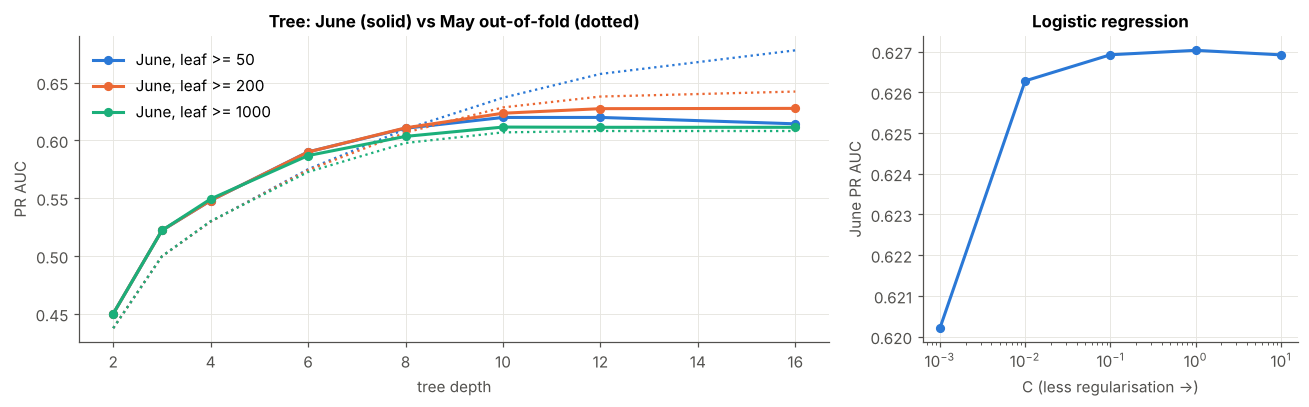

best tree: depth 16, leaf 200, June PR AUC 0.628
best logistic regression: C = 1.0, June PR AUC 0.627


In [13]:
tree_grid = []
for leaf in [50, 200, 1000]:
    for d in [2, 3, 4, 6, 8, 10, 12, 16]:
        m_ = make_model(make_tree(d, min_samples_leaf=leaf), KEPT, scale=False).fit(Xtr, ytr)
        tree_grid.append({"max_depth": d, "min_samples_leaf": leaf,
                          "May PR AUC": average_precision_score(ytr, m_.predict_proba(Xtr)[:, 1]),
                          "June PR AUC": average_precision_score(yva, m_.predict_proba(Xva)[:, 1])})
tree_grid = pd.DataFrame(tree_grid)
best_tree = tree_grid.loc[tree_grid["June PR AUC"].idxmax()]

lr_grid = pd.DataFrame([{"C": C, "June PR AUC": average_precision_score(
    yva, make_model(make_logreg(C), KEPT).fit(Xtr, ytr).predict_proba(Xva)[:, 1])} for C in [0.001, 0.01, 0.1, 1, 10]])
best_C = float(lr_grid.loc[lr_grid["June PR AUC"].idxmax(), "C"])

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [2, 1]})
for leaf, col in zip([50, 200, 1000], [BLUE, ORANGE, AQUA]):
    g = tree_grid[tree_grid.min_samples_leaf == leaf]
    ax[0].plot(g.max_depth, g["June PR AUC"], color=col, marker="o", ms=5, label=f"June, leaf >= {leaf}")
    ax[0].plot(g.max_depth, g["May PR AUC"], color=col, ls=":", lw=1.5)
ax[0].set(xlabel="tree depth", ylabel="PR AUC"); ax[0].set_title("Tree: June (solid) vs May out-of-fold (dotted)")
ax[0].legend(frameon=False)
ax[1].plot(lr_grid.C, lr_grid["June PR AUC"], color=BLUE, marker="o", ms=5); ax[1].set_xscale("log")
ax[1].set(xlabel="C (less regularisation ->)", ylabel="June PR AUC"); ax[1].set_title("Logistic regression")
fig.tight_layout(); fig.savefig(FIG / "03_tuning.png", bbox_inches="tight"); plt.show()
print(f"best tree: depth {int(best_tree.max_depth)}, leaf {int(best_tree.min_samples_leaf)}, June PR AUC {best_tree['June PR AUC']:.3f}")
print(f"best logistic regression: C = {best_C}, June PR AUC {lr_grid['June PR AUC'].max():.3f}")

## 7. Where we stand on June
The two tuned models, refitted as **full pipelines from raw rows**, next to the baseline ladder from notebook 01. Precision, recall and cost are shown at the **break-even threshold** 1 / (1 + 3) = 0.25 implied by the costs in `PROBLEM.md` (a missed crawl costs 3, a needless warning 1). The threshold itself is chosen properly in notebook 04.

In [14]:
THR = COST_FP / (COST_FP + COST_FN)
final_lr = make_pipeline(make_logreg(best_C), KEPT, scale=True).fit(train, ytr)
final_tree = make_pipeline(make_tree(int(best_tree.max_depth), min_samples_leaf=int(best_tree.min_samples_leaf)),
                           KEPT, scale=False).fit(train, ytr)
rule = BusyRule().fit(train)
tree2 = make_tree(2).fit(Xtr[ALL_FEATS], ytr)
summary = metrics_table({
    "1 always 'no crawl'": (AlwaysNo().predict_proba(val)[:, 1], THR),
    "2 busy-hours rule": (rule.predict_proba(val)[:, 1], THR),
    "3 depth-2 tree": (tree2.predict_proba(Xva[ALL_FEATS])[:, 1], THR),
    "logistic regression": (final_lr.predict_proba(val)[:, 1], THR),
    f"decision tree (depth {int(best_tree.max_depth)})": (final_tree.predict_proba(val)[:, 1], THR),
}, yva)
summary.round(3)

,pr_auc,precision,recall,lift@10%,pr_auc_lift,warned_%,base_rate,cost_per_1000
1 always 'no crawl',0.185,0.000,0.000,1.235,1.000,0.000,0.185,556.063
2 busy-hours rule,0.244,0.307,0.480,1.769,1.315,28.957,0.185,490.090
3 depth-2 tree,0.450,0.462,0.607,3.333,2.428,24.346,0.185,349.493
logistic regression,0.627,0.497,0.729,3.831,3.383,27.184,0.185,287.452
decision tree (depth 16),0.628,0.468,0.766,3.816,3.387,30.325,0.185,291.642


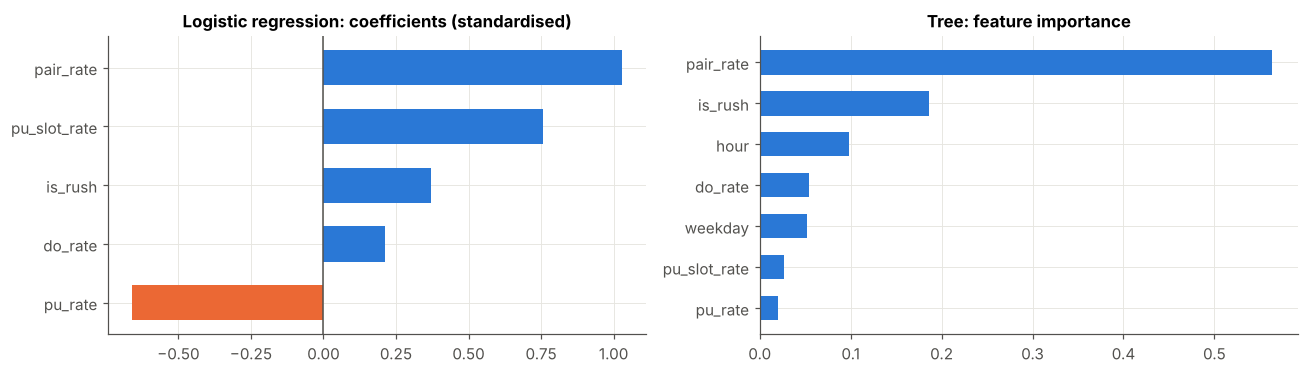

In [15]:
coefs = pd.Series(final_lr.named_steps["model"].coef_[0],
                  index=final_lr.named_steps["prep"].get_feature_names_out()).sort_values()
imp = pd.Series(final_tree.named_steps["model"].feature_importances_, index=KEPT).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(12, max(3.5, 0.28 * len(KEPT))))
c = coefs[~coefs.index.str.startswith("cat__")]
ax[0].barh(c.index.str.replace("num__", ""), c.values, color=[ORANGE if v < 0 else BLUE for v in c.values], height=0.6)
ax[0].axvline(0, color=INK, lw=1); ax[0].set_title("Logistic regression: coefficients (standardised)")
ax[1].barh(imp.index, imp.values, color=BLUE, height=0.6); ax[1].set_title("Tree: feature importance")
fig.tight_layout(); fig.savefig(FIG / "03_model_weights.png", bbox_inches="tight"); plt.show()

In [16]:
choice = {"features": KEPT, "min_gain": MIN_GAIN,
          "tree": {"max_depth": int(best_tree.max_depth), "min_samples_leaf": int(best_tree.min_samples_leaf)},
          "logreg": {"C": best_C},
          "june": summary[["pr_auc", "pr_auc_lift", "lift@10%"]].round(4).to_dict(orient="index")}
(REPORTS / "selected_features.json").write_text(json.dumps(choice, indent=2))
print("saved reports/selected_features.json for notebook 04")

saved reports/selected_features.json for notebook 04


## Summary
* **Pipeline:** `make_pipeline(model, features)` in `src/features.py` takes raw trip rows and returns a crawl probability. All learned statistics come from May, out-of-fold within May. Notebook 04 refits nothing from June: it loads `reports/selected_features.json` and fits the same pipeline on May.
* **Leak tests:** blanking every forbidden column of June leaves predictions unchanged; statistics come from May only; shuffled labels give no skill; the in-sample version shows the gap that out-of-fold statistics prevent.
* **Features:** each group and each single feature was judged on June. The tables in section 5 list what was kept, what lost, and what was never allowed (with the oracle showing how much the planned-distance estimate gives up).
* **Models:** a logistic regression and a single tree, tuned on June, both compared with the baseline ladder above. The final choice, the threshold from costs and the one look at July are notebook 04.